# ✈️ Engine Health Monitoring: Which Engines Need Maintenance First?

**Author:** Saad Chughtai  
**Tools:** Python (pandas, NumPy, Matplotlib) · Astrato (dashboard)  
**Data:** NASA C-MAPSS Turbofan Engine Degradation Simulation (subset FD001)

---

## The problem

Aircraft engines wear down gradually. If maintenance happens too late, an engine can fail; if it happens too early, money and engine life are wasted. Airlines and manufacturers therefore want to know **how many cycles each engine has left before it needs attention**, so they can plan maintenance at the right time.

## The data

NASA simulated 100 turbofan engines running from healthy until failure. For every flight cycle, the dataset records:

- **Engine ID** and **cycle number**
- **3 operational settings** (flight conditions)
- **21 sensor readings** (temperatures, pressures, fan and core speeds)

Subset FD001 covers one operating condition and one fault mode (high-pressure compressor degradation).

| File | Contents |
|---|---|
| `train_FD001.txt` | 100 engines recorded until failure |
| `test_FD001.txt` | 100 engines whose records stop before failure |
| `RUL_FD001.txt` | The true remaining cycles for each test engine |

## Questions this notebook answers

1. How long do engines typically last, and how much does this vary?
2. Which sensors actually change as an engine wears out, and which can be ignored?
3. How can each engine be grouped into **Healthy**, **Watch** or **Critical**?
4. Across the current fleet, which engines need maintenance first?

## Notebook structure

1. Load the data
2. Remaining useful life (RUL)
3. Sensor selection
4. Visualising engine wear
5. Health status
6. Fleet snapshot
7. Export for the dashboard

---

*Data source: A. Saxena, K. Goebel, D. Simon and N. Eklund, "Damage Propagation Modeling for Aircraft Engine Run-to-Failure Simulation", PHM08, 2008. NASA Prognostics Center of Excellence Data Set Repository.*

## 1) Import the data

In [1]:
# Imports
import pandas as pd
import numpy as np
import zipfile 
import matplotlib.pyplot as plt

ZIP_PATH = "data/NASA_CMAPSS_FD001.zip"

#Column names: engine id, cycle, 3 operational settings, 21 sensors
sensor_cols = ["s" + str(x) for x in range(1, 22)]
setting_cols = ["op_1", "op_2", "op_3"]
col_names = ["unit", "cycle"] + setting_cols + sensor_cols

# Open each file inside the zip file and pass it to pandas
with zipfile.ZipFile(ZIP_PATH) as z:
    print(z.namelist())
    with z.open("train_FD001.txt") as f:
        train = pd.read_csv(f, sep=r"\s+", header=None, names=col_names)
    with z.open("test_FD001.txt") as f:
        test = pd.read_csv(f, sep=r"\s+", header=None, names=col_names)
    with z.open("RUL_FD001.txt") as f:
        true_rul = pd.read_csv(f, sep=r"\s+", header=None, names=["true_RUL"])

print("Train:", train.shape, "| Test:", test.shape, "| True RUL:", true_rul.shape)
train.head()
    


['README.txt', 'RUL_FD001.txt', 'test_FD001.txt', 'train_FD001.txt']
Train: (20631, 26) | Test: (13096, 26) | True RUL: (100, 1)


,unit,cycle,op_1,op_2,op_3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


### Key Insights
- The NASA files are inside a zip, so I open each file directly from the zip instead of extracting it first.
- The text files have no header row and use spaces between values, so I supply the 26 column names myself: engine ID (`unit`), `cycle`, 3 operational settings and 21 sensors.
- I load three files: `train` (100 engines run until failure), `test` (100 engines whose records stop before failure) and `true_rul` (how many cycles each test engine actually had left).
- The training data has **20,631 rows and 26 columns**.

## 2) Check the data

In [2]:
print("Missing values:", train.isna().sum().sum())
print("Number of engines:", train["unit"].nunique())

lifetimes = train.groupby("unit")["cycle"].max()
lifetimes.describe()

Missing values: 0
Number of engines: 100


count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64

### Key Insights
- There are **no missing values**, so no rows need to be removed or filled in.
- The training data covers **100 engines**.
- Engines last between **128 and 362 cycles** before failing, with an average of about **206 cycles**.
- That's a wide range, which shows why maintenance can't simply be scheduled at a fixed number of cycles for every engine.

## 3) Remaining useful life (RUL)

Every engine ends at RUL 0: True


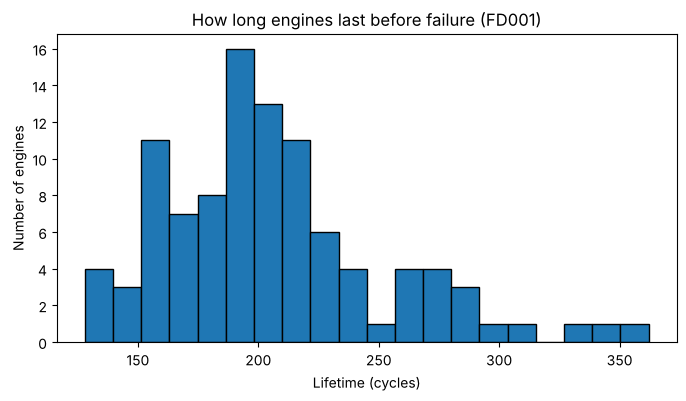

In [3]:
# RUL = how many cycles each engine has left before it fails
train["max_cycle"] = train.groupby("unit")["cycle"].transform("max")
train["RUL"] = train["max_cycle"] - train["cycle"]
train = train.drop(columns="max_cycle")

# Check: every engine's last row should have no remaining useful life
print("Every engine ends at RUL 0:", (train.groupby("unit")["RUL"].min() == 0).all())

# Histogram of engine lifetimes
plt.figure(figsize=(8, 4))
plt.hist(lifetimes, bins=20, edgecolor="black")
plt.title("How long engines last before failure (FD001)")
plt.xlabel("Lifetime (cycles)")
plt.ylabel("Number of engines")
plt.show()

### Key Insights
- **RUL is the number of flight cycles an engine has left before it fails.** For a maintenance engineer, it answers: "how long can this engine keep flying before it needs attention?"
- In the training data every engine runs until failure, so RUL = the engine's final cycle minus its current cycle.
- I checked that every engine's last row has an RUL of 0, which confirms the calculation is correct.
- The histogram shows most engines last roughly 175–230 cycles, with a few lasting much longer.

## 4) Find the sensors that don't change

In [4]:
# Sensors with almost no variation cannot tell us anything about wear
stds = train[setting_cols + sensor_cols].std().sort_values()
print(stds.round(4))

flat_cols = stds[stds < 0.01].index.tolist()
useful_sensors = [c for c in sensor_cols if c not in flat_cols]
print("Dropping:", flat_cols)
print("Keeping:", useful_sensors)

s1       0.0000
op_3     0.0000
s10      0.0000
s19      0.0000
s18      0.0000
s16      0.0000
s5       0.0000
op_2     0.0003
s6       0.0014
op_1     0.0022
s15      0.0375
s8       0.0710
s13      0.0719
s21      0.1083
s20      0.1807
s11      0.2671
s2       0.5001
s12      0.7376
s7       0.8851
s17      1.5488
s3       6.1311
s4       9.0006
s14     19.0762
s9      22.0829
dtype: float64
Dropping: ['s1', 'op_3', 's10', 's19', 's18', 's16', 's5', 'op_2', 's6', 'op_1']
Keeping: ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


### Key Insights
- A sensor that gives almost the same reading every cycle can't tell us anything about wear, so it only adds noise.
- I measured how much each column varies (standard deviation) and dropped any with almost no variation (below 0.01).
- **Dropped:** sensors s1, s5, s6, s10, s16, s18 and s19, plus the 3 operational settings. FD001 uses a single flight condition, so the settings barely change.
- **Kept:** 14 sensors that actually change as the engine runs.

## 5) Which sensors track wear?

s11   -0.70
s4    -0.68
s15   -0.64
s2    -0.61
s17   -0.61
s3    -0.58
s8    -0.56
s13   -0.56
s9    -0.39
s14   -0.31
s20    0.63
s21    0.64
s7     0.66
s12    0.67
Name: RUL, dtype: float64


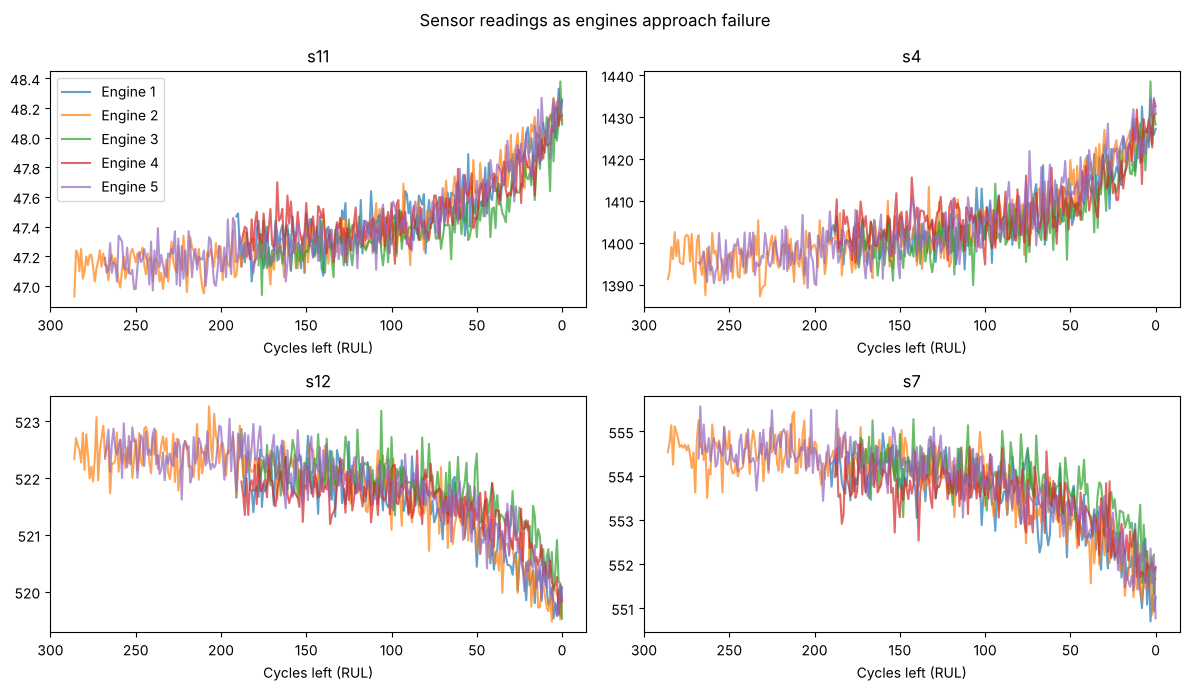

In [5]:
# Correlation of each useful sensor with RUL
corr = train[useful_sensors + ["RUL"]].corr()["RUL"].drop("RUL").sort_values()
print(corr.round(2))

# Plot the 4 strongest sensors against RUL for a few engines
top_sensors = corr.abs().sort_values(ascending=False).head(4).index.tolist()
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, sensor in zip(axes.flat, top_sensors):
    for unit in [1, 2, 3, 4, 5]:
        engine = train[train["unit"] == unit]
        ax.plot(engine["RUL"], engine[sensor], alpha=0.7, label=f"Engine {unit}")
    ax.invert_xaxis()
    ax.set_title(sensor)
    ax.set_xlabel("Cycles left (RUL)")
axes[0, 0].legend()
plt.suptitle("Sensor readings as engines approach failure")
plt.tight_layout()
plt.show()

### Key Insights
- I measured how strongly each remaining sensor is linked to RUL (correlation).
- The four strongest were **s11** (HPC outlet static pressure, −0.70), **s4** (LPT outlet temperature, −0.68), **s12** (fuel flow to pressure ratio, +0.67) and **s7** (HPC outlet pressure, +0.66).
- The charts show a clear pattern for engines 1–5:
  - **s11 and s4 rise** as engines approach failure: pressure and temperature build up.
  - **s12 and s7 fall** as engines approach failure.
  - The change is small for most of each engine's life, then **speeds up in the last ~50 cycles**.
- This makes sense, because FD001 simulates wear in the **high-pressure compressor (HPC)**, and the strongest signals come from compressor pressure and temperature sensors.
- A negative correlation means the reading goes **up** as RUL goes down, because RUL counts down towards failure.

## 6) Health Status

In [6]:
def health_status(rul):
    if rul <= 20:
        return "Critical"
    elif rul <= 50:
        return "Watch"
    return "Healthy"

train["status"] = train["RUL"].apply(health_status)
train["status"].value_counts()

status
Healthy     15531
Watch        3000
Critical     2100
Name: count, dtype: int64

### Key Insights
- To make the results useful for a maintenance team, I grouped every reading into three categories:
  - **Critical:** 20 cycles or fewer left. Needs maintenance now.
  - **Watch:** 21–50 cycles left. Plan maintenance soon.
  - **Healthy:** more than 50 cycles left.
- I chose 20 and 50 cycles to leave enough time to schedule work and order parts. In a real airline these cut-offs would be agreed with engineers.

## 7) Fleet snapshot (“today”)

In [7]:
# Test engines stop before failure: take each engine's latest reading
fleet = test.groupby("unit").tail(1).reset_index(drop=True)
fleet["RUL"] = true_rul["true_RUL"].values  # line 1 of RUL file = engine 1, etc.
fleet["status"] = fleet["RUL"].apply(health_status)

print(fleet["status"].value_counts())
fleet.sort_values("RUL")[["unit", "cycle", "RUL", "status"]].head(10)   # most urgent first

status
Healthy     67
Watch       17
Critical    16
Name: count, dtype: int64


,unit,cycle,RUL,status
33,34,203,7,Critical
30,31,196,8,Critical
80,81,213,8,Critical
67,68,187,8,Critical
81,82,162,9,Critical
75,76,205,10,Critical
41,42,156,10,Critical
34,35,198,11,Critical
65,66,147,14,Critical
55,56,136,15,Critical


### Key Insights
- The test engines stop before failure, so each one's latest reading shows where the fleet stands "today".
- Combining these with NASA's true RUL values gives the current status of all 100 engines:
  - **67 Healthy, 17 Watch, 16 Critical**
- The most urgent engines have only **7–8 cycles left** (engine 34 first, then engines 31, 81 and 68).
- This is the list a maintenance planner would act on first.

## 8) Export for Astrato

In [8]:
keep = ["unit", "cycle"] + useful_sensors + ["RUL", "status"]

train[keep].to_csv("data/engine_history.csv", index=False)
fleet[keep].to_csv("data/fleet_snapshot.csv", index=False)
print("Saved engine_history.csv and fleet_snapshot.csv")

Saved engine_history.csv and fleet_snapshot.csv


### Key Insights
- I saved two clean files for the Astrato dashboard:
  - `engine_history.csv`: every cycle for every training engine, with the useful sensors, RUL and status. Used for sensor trend charts.
  - `fleet_snapshot.csv`: one row per test engine, with its current RUL and status. Used for the fleet overview and the "most urgent" table.
- Only the useful sensors are kept, so the dashboard stays simple and fast.